# Proyecto práctico — Módulo 3 · Otoño 2026

**Nombre:** Maria Fernanda Gómez Flores
**Modalidad:** proyecto para entregar  
**Total:** 100 puntos

## El problema

Un servicio de bicicletas compartidas quiere entender y estimar cuántas bicicletas se alquilan por hora según el horario, el calendario y el clima. Te entrega **`bicicletas_seoul_examen3.csv`**, con 8,760 registros horarios del servicio de Seúl, entre diciembre de 2017 y noviembre de 2018.

Realiza el análisis completo: prepara la base, explora sus relaciones, compara modelos, explica sus predicciones y recomienda una solución. La variable objetivo es **`rented_bike_count`**. Trabaja solo con las horas en que el servicio funcionó: **`functioning_day = Yes`**.

Para este ejercicio se consideran conocidas las condiciones meteorológicas de cada hora. Se evalúa la estimación de demanda dadas esas condiciones; para convertirla en un pronóstico anticipado habría que disponer de pronósticos del clima y volver a evaluar el sistema.

## Consigna y entrega

Usa **árboles de decisión, Random Forest, XGBoost, LightGBM y CatBoost**. Explica el modelo elegido con **SHAP** y evalúa el efecto de aplicar **PCA**.

Entrega un notebook ejecutado con código, tablas, gráficas y una **conclusión con tus propias palabras en cada sección**: qué hiciste, por qué, qué encontraste y qué significa. No basta con correr modelos ni con obtener el menor error. Adjunta el CSV y usa rutas relativas para que el trabajo pueda reproducirse.

## Reglas de comparación

- **Entrenamiento:** hasta el 30 de septiembre de 2018. **Validación:** octubre de 2018. **Prueba:** noviembre de 2018. Conserva esas mismas fechas y filas para todos los modelos.
- Elige variables, transformaciones, hiperparámetros y modelo final con entrenamiento y validación. Reserva noviembre hasta fijar las decisiones. Al final evalúa una sola vez las configuraciones elegidas para construir la comparación; no vuelvas a ajustarlas con noviembre.
- Ajusta imputación, codificación aprendida, escalamiento y PCA solo con entrenamiento. La variable objetivo no debe formar parte de los predictores ni de PCA.
- Usa **MAE como métrica principal** y reporta también RMSE, ambos en número de bicicletas. Si transformas el objetivo, calcula los errores después de volver a su escala original.
- Documenta tu preparación, usa semillas y registra las versiones de las bibliotecas.

## Puntaje

| Sección | Puntos |
|---|---:|
| 1. Preparación | 5 |
| 2. Exploración | 5 |
| 3. Referencia y árboles de decisión | 12 |
| 4. Random Forest | 18 |
| 5. XGBoost, LightGBM y CatBoost | 30 |
| 6. SHAP | 12 |
| 7. PCA | 10 |
| 8. Comparación y recomendación | 8 |
| **Total** | **100** |

## Diccionario de variables

Una fila representa una fecha y una hora del servicio, no una bicicleta ni un usuario individual. Los nombres se simplificaron para trabajar con Python y las fechas se escribieron como año-mes-día.

| Variable | Descripción | Unidad o valores |
|---|---|---|
| `rented_bike_count` | **Objetivo:** cantidad de bicicletas alquiladas en esa hora | Conteo |
| `date` | Fecha | AAAA-MM-DD |
| `hour` | Hora del día | 0 a 23 |
| `temperature` | Temperatura del aire | °C |
| `humidity` | Humedad relativa | % |
| `wind_speed` | Velocidad del viento | m/s |
| `visibility` | Visibilidad | Unidades de 10 metros; 2,000 equivale a 20,000 metros |
| `dew_point_temperature` | Temperatura del punto de rocío | °C |
| `solar_radiation` | Radiación solar | MJ/m² |
| `rainfall` | Lluvia | mm |
| `snowfall` | Nieve | cm |
| `season` | Estación del año | Winter, Spring, Summer, Autumn |
| `holiday` | Indicador de feriado | Holiday, No Holiday |
| `functioning_day` | Indica si el servicio funcionaba | Yes, No; conservar solo Yes |

**Fuente:** [Seoul Bike Sharing Demand, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/560/seoul%2Bbike%2Bsharing%2Bdemand). Easwaramoorthy, S. (2020). DOI: [10.24432/C5F62R](https://doi.org/10.24432/C5F62R). Licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). La entrega conserva todos los registros y valores originales; solo cambia nombres de columnas, representación de fechas, orden y codificación a UTF-8.

## 1. Entender y preparar los datos (5 puntos)

Revisa tipos de variables, faltantes, duplicados y rangos. Filtra las horas en que funcionaba el servicio y prepara los datos para modelar. Muestra cuántas observaciones y qué fechas tiene cada partición.

**Conclusión:** ¿qué representa una observación, qué decisiones de preparación tomaste y por qué? Si no hay faltantes o duplicados, repórtalo; no es necesario inventar problemas de limpieza.

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [56]:
import sklearn as sk
import xgboost as xgb
import lightgbm as lgb
import catboost
import shap

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

In [57]:
df = pd.read_csv('bicicletas_seoul_examen3.csv')
df.head()

,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,season,holiday,functioning_day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [58]:
df.dtypes

date                      object
rented_bike_count          int64
hour                       int64
temperature              float64
humidity                   int64
wind_speed               float64
visibility                 int64
dew_point_temperature    float64
solar_radiation          float64
rainfall                 float64
snowfall                 float64
season                    object
holiday                   object
functioning_day           object
dtype: object

In [59]:
df.isna().sum()

date                     0
rented_bike_count        0
hour                     0
temperature              0
humidity                 0
wind_speed               0
visibility               0
dew_point_temperature    0
solar_radiation          0
rainfall                 0
snowfall                 0
season                   0
holiday                  0
functioning_day          0
dtype: int64

In [60]:
df.duplicated().sum()

np.int64(0)

In [61]:
df.describe().round(2)

,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall
count,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00
mean,704.60,11.50,12.88,58.23,1.72,1436.83,4.07,0.57,0.15,0.08
std,645.00,6.92,11.94,20.36,1.04,608.30,13.06,0.87,1.13,0.44
min,0.00,0.00,-17.80,0.00,0.00,27.00,-30.60,0.00,0.00,0.00
25%,191.00,5.75,3.50,42.00,0.90,940.00,-4.70,0.00,0.00,0.00
50%,504.50,11.50,13.70,57.00,1.50,1698.00,5.10,0.01,0.00,0.00
75%,1065.25,17.25,22.50,74.00,2.30,2000.00,14.80,0.93,0.00,0.00
max,3556.00,23.00,39.40,98.00,7.40,2000.00,27.20,3.52,35.00,8.80


In [62]:
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')
df = df[df['functioning_day'] == 'Yes'].copy()

In [63]:
df['month'] = df['date'].dt.month
df['day_of_month'] = df['date'].dt.day
df['week_of_year'] = df['date'].dt.isocalendar().week.astype(int)

In [64]:
train_df = df[df['date'] <= '2018-09-30'].copy()
valid_df = df[(df['date'] >= '2018-10-01') & (df['date'] <= '2018-10-31')].copy()
test_df = df[(df['date'] >= '2018-11-01') & (df['date'] <= '2018-11-30')].copy()

print(train_df.shape, train_df['date'].min(), train_df['date'].max())
print(valid_df.shape, valid_df['date'].min(), valid_df['date'].max())
print(test_df.shape, test_df['date'].min(), test_df['date'].max())

(7152, 17) 2017-12-01 00:00:00 2018-09-29 00:00:00
(665, 17) 2018-10-01 00:00:00 2018-10-31 00:00:00
(648, 17) 2018-11-01 00:00:00 2018-11-30 00:00:00


In [65]:
target = 'rented_bike_count'

train_modelo = train_df.drop(columns=['date', 'functioning_day'])
valid_modelo = valid_df.drop(columns=['date', 'functioning_day'])
test_modelo = test_df.drop(columns=['date', 'functioning_day'])

X_train = pd.get_dummies(train_modelo.drop(columns=target))
y_train = train_modelo[target]

X_valid = pd.get_dummies(valid_modelo.drop(columns=target))
y_valid = valid_modelo[target]

X_test = pd.get_dummies(test_modelo.drop(columns=target))
y_test = test_modelo[target]

X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [66]:
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('sklearn:', sk.__version__)
print('xgboost:', xgb.__version__)
print('lightgbm:', lgb.__version__)
print('catboost:', catboost.__version__)
print('shap:', shap.__version__)

pandas: 2.2.3
numpy: 2.1.3
sklearn: 1.6.1
xgboost: 3.4.1
lightgbm: 4.7.0
catboost: 1.2.10
shap: 0.50.0


cada fila representa una hora del servicio y cuantas bicicletas se rentaron en esa hora. revise tipos faltantes duplicados y rangos y no hay faltantes ni duplicados entonces no tuve que hacer otra limpieza

filtre functioning_day para quedarme solo con las horas donde si estaba funcionando y converti date para separar los datos por tiempo. tmb saque mes dia y semana porque pueden ayudar a captar cambios durante el año

train termina el 29 de septiembre porque el 30 todas las observaciones estaban como No en functioning_day

## 2. Explorar y formular hipótesis (5 puntos)

Usando entrenamiento, construye al menos tres gráficas que ayuden a entender la demanda: por hora, por calendario o frente a condiciones del clima. Puedes crear variables de calendario si explicas su utilidad.

**Conclusión:** describe dos patrones que esperas que aprendan los modelos y algo que las gráficas no permitan concluir.

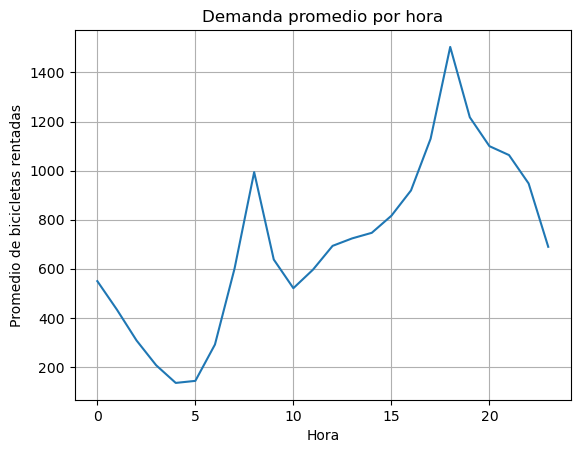

In [67]:
promedio_hora = train_df.groupby('hour').rented_bike_count.mean()

plt.plot(promedio_hora.index, promedio_hora.values)
plt.xlabel("Hora")
plt.ylabel("Promedio de bicicletas rentadas")
plt.title("Demanda promedio por hora")
plt.grid()

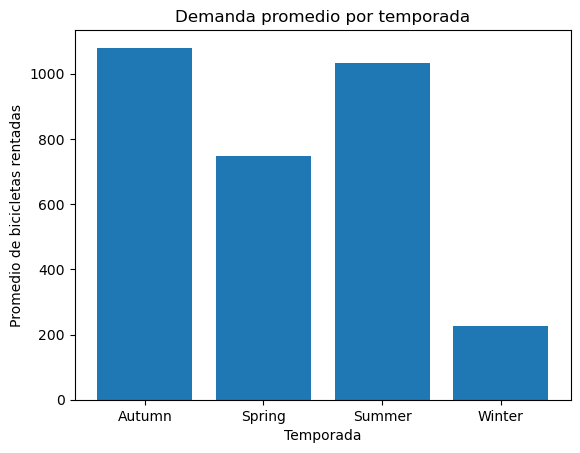

In [68]:
promedio_temporada = train_df.groupby('season').rented_bike_count.mean()

plt.bar(promedio_temporada.index, promedio_temporada.values)
plt.xlabel("Temporada")
plt.ylabel("Promedio de bicicletas rentadas")
plt.title("Demanda promedio por temporada")
plt.show()

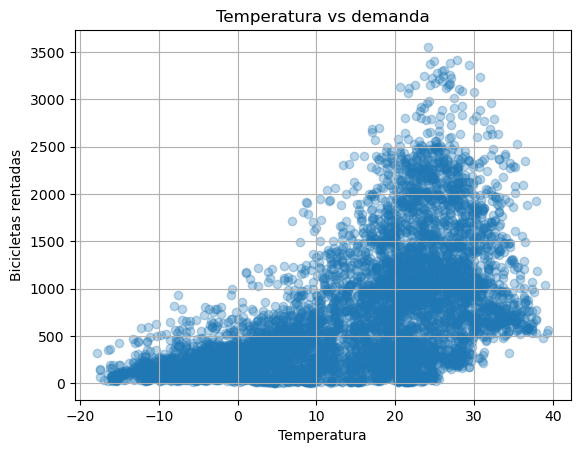

In [69]:
plt.scatter(train_df['temperature'], train_df['rented_bike_count'], alpha=0.3)
plt.xlabel("Temperatura")
plt.ylabel("Bicicletas rentadas")
plt.title("Temperatura vs demanda")
plt.grid()

se ve que la demanda cambia bastante dependiendo de la hora entonces esperaria que hour sea importante. tmb cambia por temporada y con temperaturas mas altas en general se ven mas bicicletas rentadas

pero estas graficas solo muestran relaciones osea no puedo decir que una variable este causando directamente el cambio en la demanda

## 3. Referencia y árboles de decisión (12 puntos)

Construye una referencia que prediga para cada hora del día su promedio de alquileres en entrenamiento. Entrena árboles de regresión con al menos tres niveles distintos de complejidad y compara entrenamiento y validación.

Elige un árbol con validación, muestra una parte que puedas interpretar y explica dos decisiones y una predicción de una región final.

**Conclusión:** ¿mejora la referencia? ¿Hay sobreajuste o un modelo demasiado simple? ¿Qué complejidad elegirías?

In [70]:
promedio_por_hora = train_df.groupby('hour').rented_bike_count.mean()

pred_base_train = train_df['hour'].map(promedio_por_hora)
pred_base_valid = valid_df['hour'].map(promedio_por_hora)

mae_base_train = np.mean(np.abs(y_train - pred_base_train))
mae_base_valid = np.mean(np.abs(y_valid - pred_base_valid))

rmse_base_train = np.sqrt(mean_squared_error(y_true=y_train, y_pred=pred_base_train))
rmse_base_valid = np.sqrt(mean_squared_error(y_true=y_valid, y_pred=pred_base_valid))

In [71]:
model_arbol_3 = DecisionTreeRegressor(
    max_depth=3, random_state=42, max_features='sqrt'
)
model_arbol_3.fit(X_train, y_train)

pred_arbol_3_train = model_arbol_3.predict(X_train)
pred_arbol_3_valid = model_arbol_3.predict(X_valid)

In [72]:
model_arbol_6 = DecisionTreeRegressor(
    max_depth=6, random_state=42, max_features='sqrt'
)
model_arbol_6.fit(X_train, y_train)

pred_arbol_6_train = model_arbol_6.predict(X_train)
pred_arbol_6_valid = model_arbol_6.predict(X_valid)

In [73]:
model_arbol_10 = DecisionTreeRegressor(
    max_depth=10, random_state=42, max_features='sqrt'
)
model_arbol_10.fit(X_train, y_train)

pred_arbol_10_train = model_arbol_10.predict(X_train)
pred_arbol_10_valid = model_arbol_10.predict(X_valid)

In [74]:
comparacion_arboles = pd.DataFrame({
    'Modelo': ['Baseline', 'Arbol 3', 'Arbol 6', 'Arbol 10'],
    'MAE train': [
        mae_base_train,
        np.mean(np.abs(y_train - pred_arbol_3_train)),
        np.mean(np.abs(y_train - pred_arbol_6_train)),
        np.mean(np.abs(y_train - pred_arbol_10_train))
    ],
    'MAE validacion': [
        mae_base_valid,
        np.mean(np.abs(y_valid - pred_arbol_3_valid)),
        np.mean(np.abs(y_valid - pred_arbol_6_valid)),
        np.mean(np.abs(y_valid - pred_arbol_10_valid))
    ]
})
comparacion_arboles.round(2)

,Modelo,MAE train,MAE validacion
0,Baseline,435.55,384.72
1,Arbol 3,360.91,486.69
2,Arbol 6,280.82,426.28
3,Arbol 10,175.40,305.98


In [75]:
comparacion_arboles_rmse = pd.DataFrame({
    'Modelo': ['Baseline', 'Arbol 3', 'Arbol 6', 'Arbol 10'],
    'RMSE train': [
        rmse_base_train,
        np.sqrt(mean_squared_error(y_true=y_train, y_pred=pred_arbol_3_train)),
        np.sqrt(mean_squared_error(y_true=y_train, y_pred=pred_arbol_6_train)),
        np.sqrt(mean_squared_error(y_true=y_train, y_pred=pred_arbol_10_train))
    ],
    'RMSE validacion': [
        rmse_base_valid,
        np.sqrt(mean_squared_error(y_true=y_valid, y_pred=pred_arbol_3_valid)),
        np.sqrt(mean_squared_error(y_true=y_valid, y_pred=pred_arbol_6_valid)),
        np.sqrt(mean_squared_error(y_true=y_valid, y_pred=pred_arbol_10_valid))
    ]
})
comparacion_arboles_rmse.round(2)

,Modelo,RMSE train,RMSE validacion
0,Baseline,551.86,493.50
1,Arbol 3,510.80,643.04
2,Arbol 6,411.67,560.39
3,Arbol 10,279.87,429.32


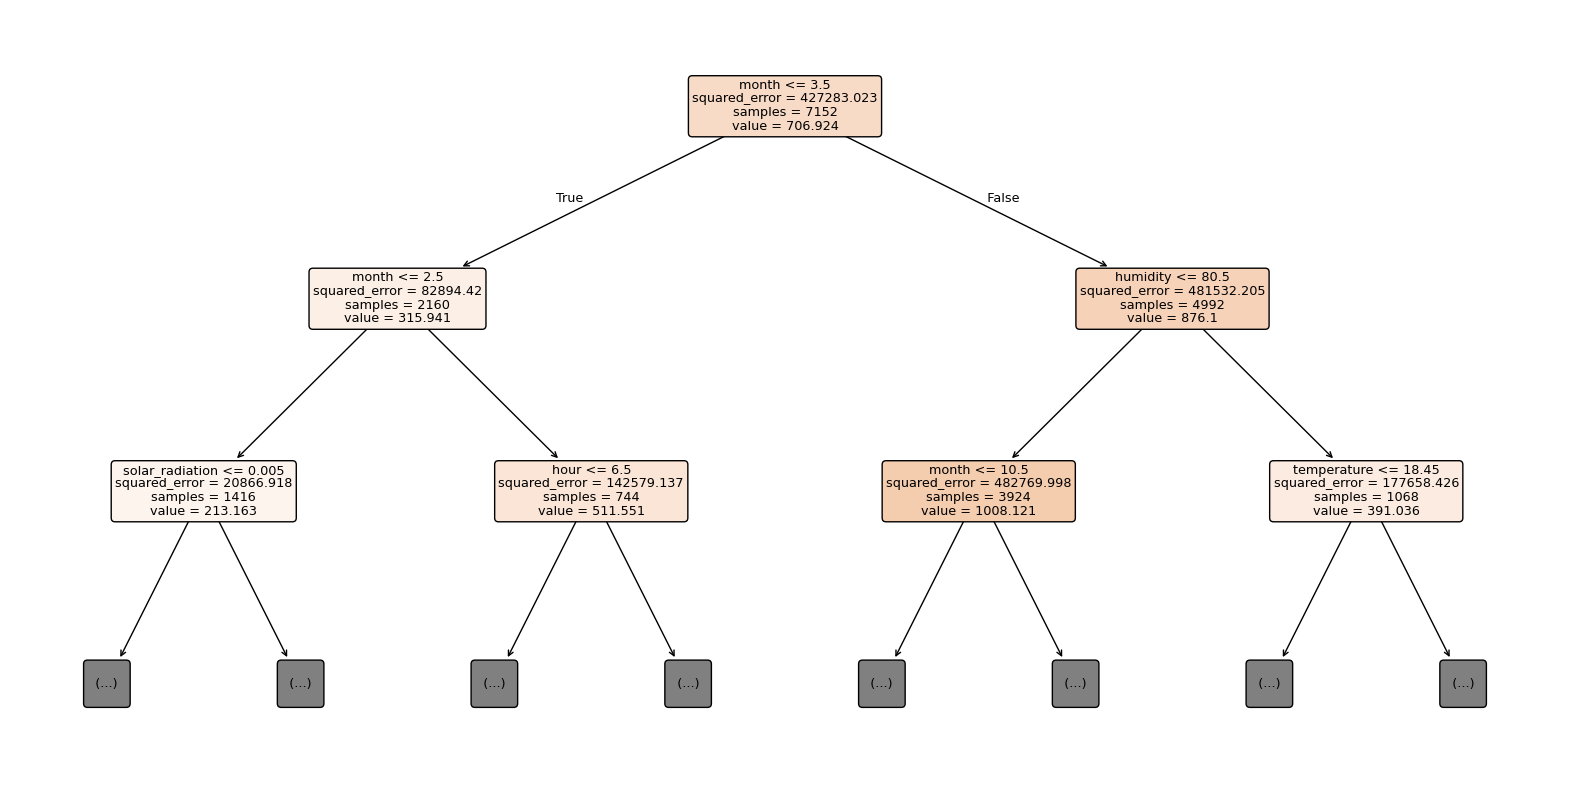

In [76]:
best_tree = model_arbol_10

plt.figure(figsize=(20, 10))
plot_tree(
    best_tree,
    feature_names=X_train.keys(),
    filled=True,
    rounded=True,
    max_depth=2
)
plt.show()

el baseline tiene un MAE de validacion de 384.72. el arbol de profundidad 3 queda peor y el de 6 tmb, el de 10 baja a 305.98 entonces de los tres escogería ese

si se nota diferencia entre train y validacion entonces tiene algo de overfitting pero aun asi es el que mejor quedo de los tres en validacion

el primer corte separa si month es menor o igual a 3.5. despues por ejemplo si month es mayor a 3.5 revisa si humidity es menor o igual a 80.5. siguiendo una de esas ramas hasta una hoja final el modelo da una prediccion de aprox 180 bicicletas

## 4. Random Forest (18 puntos)

Compara al menos tres configuraciones de Random Forest, modificando al menos dos controles como profundidad, mínimo de observaciones por hoja o `max_features`. Justifica los cambios y compara entrenamiento y validación contra el árbol elegido.

Revisa e interpreta la importancia de variables del bosque, incluyendo alguna limitación de esa medida.

**Conclusión:** ¿qué cambió al pasar de un árbol a un bosque? Relaciona tus resultados con diversidad, estabilidad y sobreajuste.

In [77]:
model_rf_1 = RandomForestRegressor(
    n_estimators=300, max_depth=6, max_features='sqrt', random_state=42
)
model_rf_1.fit(X_train, y_train)

pred_rf_1_train = model_rf_1.predict(X_train)
pred_rf_1_valid = model_rf_1.predict(X_valid)

In [78]:
model_rf_2 = RandomForestRegressor(
    n_estimators=300, max_depth=10, max_features='log2', random_state=42
)
model_rf_2.fit(X_train, y_train)

pred_rf_2_train = model_rf_2.predict(X_train)
pred_rf_2_valid = model_rf_2.predict(X_valid)

In [79]:
model_rf_3 = RandomForestRegressor(
    n_estimators=300, max_depth=12, max_features=10, random_state=42
)
model_rf_3.fit(X_train, y_train)

pred_rf_3_train = model_rf_3.predict(X_train)
pred_rf_3_valid = model_rf_3.predict(X_valid)

In [80]:
comparacion_rf = pd.DataFrame({
    'Modelo': ['RF 1', 'RF 2', 'RF 3'],
    'MAE train': [
        np.mean(np.abs(y_train - pred_rf_1_train)),
        np.mean(np.abs(y_train - pred_rf_2_train)),
        np.mean(np.abs(y_train - pred_rf_3_train))
    ],
    'MAE validacion': [
        np.mean(np.abs(y_valid - pred_rf_1_valid)),
        np.mean(np.abs(y_valid - pred_rf_2_valid)),
        np.mean(np.abs(y_valid - pred_rf_3_valid))
    ],
    'RMSE train': [
        np.sqrt(mean_squared_error(y_true=y_train, y_pred=pred_rf_1_train)),
        np.sqrt(mean_squared_error(y_true=y_train, y_pred=pred_rf_2_train)),
        np.sqrt(mean_squared_error(y_true=y_train, y_pred=pred_rf_3_train))
    ],
    'RMSE validacion': [
        np.sqrt(mean_squared_error(y_true=y_valid, y_pred=pred_rf_1_valid)),
        np.sqrt(mean_squared_error(y_true=y_valid, y_pred=pred_rf_2_valid)),
        np.sqrt(mean_squared_error(y_true=y_valid, y_pred=pred_rf_3_valid))
    ]
})
comparacion_rf.round(2)

,Modelo,MAE train,MAE validacion,RMSE train,RMSE validacion
0,RF 1,201.73,283.68,294.28,407.17
1,RF 2,129.16,250.13,200.52,368.35
2,RF 3,84.19,226.76,138.25,342.31


In [81]:
best_forest = model_rf_3

importancia_variables = pd.DataFrame({
    'variable': X_train.keys(),
    'importancia': best_forest.feature_importances_
})

importancia_variables.sort_values('importancia', ascending=False).head(10)

,variable,importancia
0,hour,0.306225
1,temperature,0.268485
2,humidity,0.093939
15,season_Winter,0.080651
6,solar_radiation,0.068003
5,dew_point_temperature,0.053638
7,rainfall,0.039768
11,week_of_year,0.036582
4,visibility,0.012446
3,wind_speed,0.011965


random forest mejoro bastante al arbol porque el RF 3 tuvo MAE de validacion de 226.76 mientras que el arbol tenia 305.98

probe distintas profundidades y max_features para ver si aumentar la complejidad mejoraba sin sobreajustar demasiado. el RF 3 fue el que mejor quedo en validacion

esto tiene sentido porque ya no depende de un solo arbol sino de muchos y al juntarlos la prediccion es mas estable aunque todavia hay diferencia entre train y validacion

las variables mas importantes fueron hour temperature humidity y season_Winter. la importancia dice cuales ayudaron mas en los cortes pero no dice si suben o bajan la demanda y tampoco demuestra causalidad

## 5. XGBoost, LightGBM y CatBoost (30 puntos)

Entrena **XGBoost, LightGBM y CatBoost**. En cada biblioteca compara al menos dos configuraciones, elige con validación y explica cómo preparaste las categorías. Puedes usar early stopping si explicas qué dato vigila.

Muestra el efecto de cambiar `learning_rate` y la complejidad o el número de árboles. Reporta errores de entrenamiento y validación; no se necesita una búsqueda exhaustiva.

**Conclusión:** explica qué aprendiste del ajuste de cada biblioteca y cómo se relaciona con su funcionamiento. ¿Cuál elegirías usando validación y por qué?

In [82]:
model_xgboost_1 = XGBRegressor(
    n_estimators=3000,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=100
)

model_xgboost_1.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_valid, y_valid)],
    verbose=50
)

[0]	validation_0-rmse:601.91727	validation_1-rmse:639.68865
[50]	validation_0-rmse:171.23548	validation_1-rmse:357.66636
[100]	validation_0-rmse:141.98105	validation_1-rmse:350.59059
[150]	validation_0-rmse:119.35955	validation_1-rmse:348.82304
[200]	validation_0-rmse:103.93894	validation_1-rmse:349.77539
[228]	validation_0-rmse:96.77940	validation_1-rmse:348.46192


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=100,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=3000,
             n_jobs=None, num_parallel_tree=None, ...)

In [83]:
model_xgboost_2 = XGBRegressor(
    n_estimators=4000,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=100
)

model_xgboost_2.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_valid, y_valid)],
    verbose=50
)

[0]	validation_0-rmse:628.92272	validation_1-rmse:658.58200


[50]	validation_0-rmse:235.39154	validation_1-rmse:398.44354
[100]	validation_0-rmse:195.90286	validation_1-rmse:368.72038
[150]	validation_0-rmse:182.29249	validation_1-rmse:353.62508
[200]	validation_0-rmse:172.16617	validation_1-rmse:346.64044
[250]	validation_0-rmse:161.57139	validation_1-rmse:345.28561
[300]	validation_0-rmse:151.97368	validation_1-rmse:339.28265
[350]	validation_0-rmse:143.98136	validation_1-rmse:341.74963
[400]	validation_0-rmse:136.40233	validation_1-rmse:342.23165


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=100,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=4000,
             n_jobs=None, num_parallel_tree=None, ...)

In [84]:
model_lightgbm_1 = lgb.LGBMRegressor(
    n_estimators=10000,
    num_leaves=31,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.5,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=0.1,
    min_child_samples=20,
    verbose=-1,
    random_state=42
)

model_lightgbm_1.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric='rmse',
    callbacks=[lgb.early_stopping(20), lgb.log_evaluation(100)],
)

Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[76]	valid_0's rmse: 383.395	valid_0's l2: 146992


/opt/anaconda3/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LGBMRegressor(colsample_bytree=0.8, max_depth=5, n_estimators=10000,
              random_state=42, reg_lambda=0.1, subsample=0.5, subsample_freq=1,
              verbose=-1)

In [85]:
model_lightgbm_2 = lgb.LGBMRegressor(
    n_estimators=10000,
    num_leaves=31,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.5,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=0.1,
    min_child_samples=20,
    verbose=-1,
    random_state=42
)

model_lightgbm_2.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric='rmse',
    callbacks=[lgb.early_stopping(20), lgb.log_evaluation(100)],
)

/opt/anaconda3/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 20 rounds
[100]	valid_0's rmse: 350.186	valid_0's l2: 122630
Early stopping, best iteration is:
[153]	valid_0's rmse: 345.068	valid_0's l2: 119072


LGBMRegressor(colsample_bytree=0.8, learning_rate=0.05, max_depth=6,
              n_estimators=10000, random_state=42, reg_lambda=0.1,
              subsample=0.5, subsample_freq=1, verbose=-1)

In [86]:
model_catboost_1 = CatBoostRegressor(
    iterations=10000,
    depth=5,
    learning_rate=0.1,
    subsample=0.5,
    rsm=0.8,
    eval_metric='R2',
    l2_leaf_reg=0.1,
    random_strength=5,
    random_seed=42,
    verbose=100,
    early_stopping_rounds=20
)

model_catboost_1.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)]
)

0:	learn: 0.0995076	test: -0.1016610	best: -0.1016610 (0)	total: 3.74ms	remaining: 37.4s
100:	learn: 0.8671219	test: 0.6167741	best: 0.6167741 (100)	total: 81.4ms	remaining: 7.98s
200:	learn: 0.9051198	test: 0.6637470	best: 0.6653680 (193)	total: 161ms	remaining: 7.86s
Stopped by overfitting detector  (20 iterations wait)

bestTest = 0.6856330733
bestIteration = 256

Shrink model to first 257 iterations.


CatBoostRegressor(depth=5, early_stopping_rounds=20, eval_metric='R2', iterations=10000, l2_leaf_reg=0.1, learning_rate=0.1, loss_function='RMSE', random_seed=42, random_strength=5, rsm=0.8, subsample=0.5, verbose=100)

In [87]:
model_catboost_2 = CatBoostRegressor(
    iterations=10000,
    depth=6,
    learning_rate=0.05,
    subsample=0.5,
    rsm=0.8,
    eval_metric='R2',
    l2_leaf_reg=0.1,
    random_strength=5,
    random_seed=42,
    verbose=100,
    early_stopping_rounds=20
)

model_catboost_2.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)]
)

0:	learn: 0.0522024	test: -0.1437501	best: -0.1437501 (0)	total: 992us	remaining: 9.92s
100:	learn: 0.8411044	test: 0.5772656	best: 0.5799583 (95)	total: 91.6ms	remaining: 8.97s
200:	learn: 0.8777627	test: 0.6326213	best: 0.6331271 (198)	total: 175ms	remaining: 8.53s
300:	learn: 0.9048618	test: 0.6703842	best: 0.6729603 (296)	total: 260ms	remaining: 8.39s
Stopped by overfitting detector  (20 iterations wait)

bestTest = 0.6747537647
bestIteration = 313

Shrink model to first 314 iterations.


CatBoostRegressor(depth=6, early_stopping_rounds=20, eval_metric='R2', iterations=10000, l2_leaf_reg=0.1, learning_rate=0.05, loss_function='RMSE', random_seed=42, random_strength=5, rsm=0.8, subsample=0.5, verbose=100)

In [88]:
pred_xgb1_train = model_xgboost_1.predict(X_train)
pred_xgb1_valid = model_xgboost_1.predict(X_valid)
pred_xgb2_train = model_xgboost_2.predict(X_train)
pred_xgb2_valid = model_xgboost_2.predict(X_valid)

pred_lgb1_train = model_lightgbm_1.predict(X_train)
pred_lgb1_valid = model_lightgbm_1.predict(X_valid)
pred_lgb2_train = model_lightgbm_2.predict(X_train)
pred_lgb2_valid = model_lightgbm_2.predict(X_valid)

pred_cat1_train = model_catboost_1.predict(X_train)
pred_cat1_valid = model_catboost_1.predict(X_valid)
pred_cat2_train = model_catboost_2.predict(X_train)
pred_cat2_valid = model_catboost_2.predict(X_valid)

In [89]:
comparacion_boosting = pd.DataFrame({
    'Modelo': ['XGB 1','XGB 2','LGB 1','LGB 2','CAT 1','CAT 2'],
    'MAE train': [
        np.mean(np.abs(y_train-pred_xgb1_train)),
        np.mean(np.abs(y_train-pred_xgb2_train)),
        np.mean(np.abs(y_train-pred_lgb1_train)),
        np.mean(np.abs(y_train-pred_lgb2_train)),
        np.mean(np.abs(y_train-pred_cat1_train)),
        np.mean(np.abs(y_train-pred_cat2_train))
    ],
    'MAE validacion': [
        np.mean(np.abs(y_valid-pred_xgb1_valid)),
        np.mean(np.abs(y_valid-pred_xgb2_valid)),
        np.mean(np.abs(y_valid-pred_lgb1_valid)),
        np.mean(np.abs(y_valid-pred_lgb2_valid)),
        np.mean(np.abs(y_valid-pred_cat1_valid)),
        np.mean(np.abs(y_valid-pred_cat2_valid))
    ]
})
comparacion_boosting.round(2)

,Modelo,MAE train,MAE validacion
0,XGB 1,83.44,243.86
1,XGB 2,98.24,232.70
2,LGB 1,123.19,265.82
3,LGB 2,113.65,236.32
4,CAT 1,123.35,241.64
5,CAT 2,128.01,241.59


In [90]:
comparacion_boosting_rmse = pd.DataFrame({
    'Modelo': ['XGB 1','XGB 2','LGB 1','LGB 2','CAT 1','CAT 2'],
    'RMSE train': [
        np.sqrt(mean_squared_error(y_train,pred_xgb1_train)),
        np.sqrt(mean_squared_error(y_train,pred_xgb2_train)),
        np.sqrt(mean_squared_error(y_train,pred_lgb1_train)),
        np.sqrt(mean_squared_error(y_train,pred_lgb2_train)),
        np.sqrt(mean_squared_error(y_train,pred_cat1_train)),
        np.sqrt(mean_squared_error(y_train,pred_cat2_train))
    ],
    'RMSE validacion': [
        np.sqrt(mean_squared_error(y_valid,pred_xgb1_valid)),
        np.sqrt(mean_squared_error(y_valid,pred_xgb2_valid)),
        np.sqrt(mean_squared_error(y_valid,pred_lgb1_valid)),
        np.sqrt(mean_squared_error(y_valid,pred_lgb2_valid)),
        np.sqrt(mean_squared_error(y_valid,pred_cat1_valid)),
        np.sqrt(mean_squared_error(y_valid,pred_cat2_valid))
    ]
})
comparacion_boosting_rmse.round(2)

,Modelo,RMSE train,RMSE validacion
0,XGB 1,127.71,348.07
1,XGB 2,151.97,339.28
2,LGB 1,193.48,383.40
3,LGB 2,178.58,345.07
4,CAT 1,189.63,348.61
5,CAT 2,199.19,354.59


de los tres tipos de boosting el mejor en validacion fue XGBoost 2 con MAE de 235.98

en XGBoost bajar el learning rate y la profundidad mejoro el resultado. en LightGBM la segunda configuracion tmb mejoro bastante y en CatBoost las dos quedaron casi iguales pero la segunda tuvo un MAE un poquito menor

las categorias las pase con get_dummies igual que en los ejercicios y validacion y test tienen las mismas columnas que train. el early stopping esta usando validacion para parar cuando ya no mejora

de estos tres yo escogería XGBoost 2 porque fue el que tuvo menor MAE en validacion

## 6. Explicar con SHAP (12 puntos)

Elige el mejor modelo de árboles usando validación y analízalo con SHAP. Puedes usar una muestra fija de hasta 500 horas de validación.

Incluye una explicación global y dos individuales con predicciones distintas. Conserva nombres interpretables para las variables y aclara la escala de los valores SHAP.

**Conclusión:** ¿qué variables importan en conjunto y cuáles elevan o reducen cada predicción respecto de su referencia? Compara con las importancias del bosque y explica por qué no demuestra causalidad.

In [91]:
shap.initjs()

X_shap = X_valid.sample(100, random_state=42)
explainer = shap.TreeExplainer(best_forest)
shap_values = explainer.shap_values(X_shap)

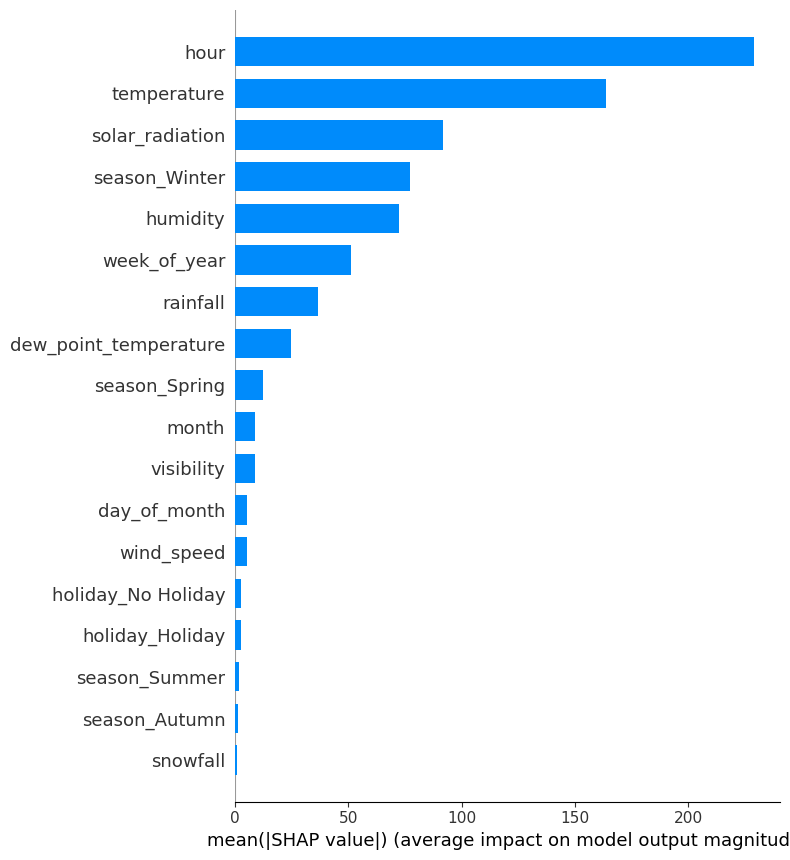

In [92]:
shap.summary_plot(shap_values, X_shap, plot_type='bar')

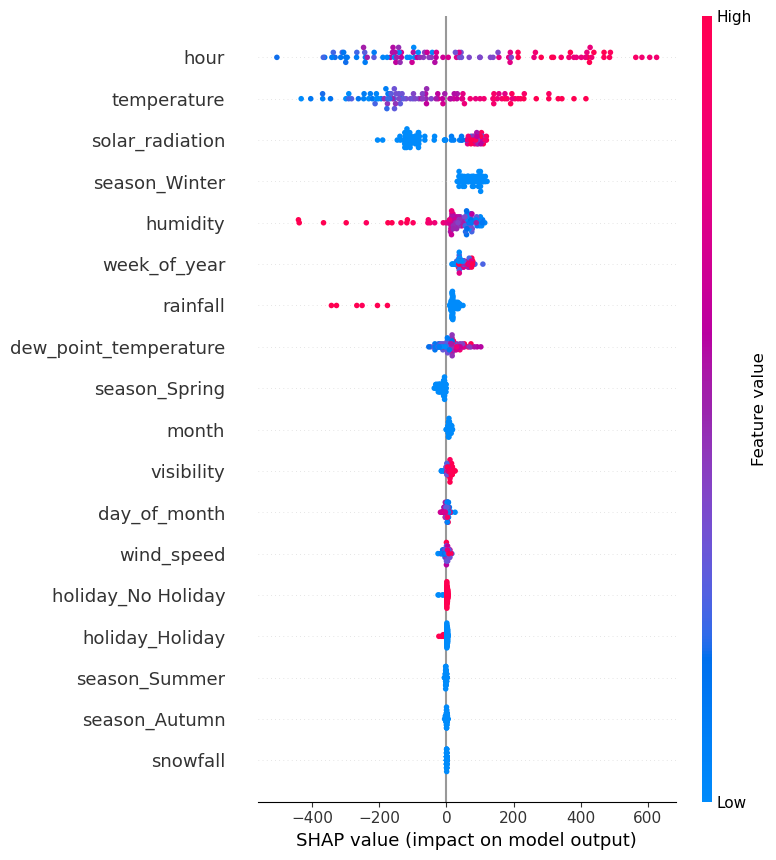

In [93]:
shap.summary_plot(shap_values, X_shap)

In [94]:
predicciones_shap = best_forest.predict(X_shap)
indice_bajo = np.argmin(predicciones_shap)
indice_alto = np.argmax(predicciones_shap)

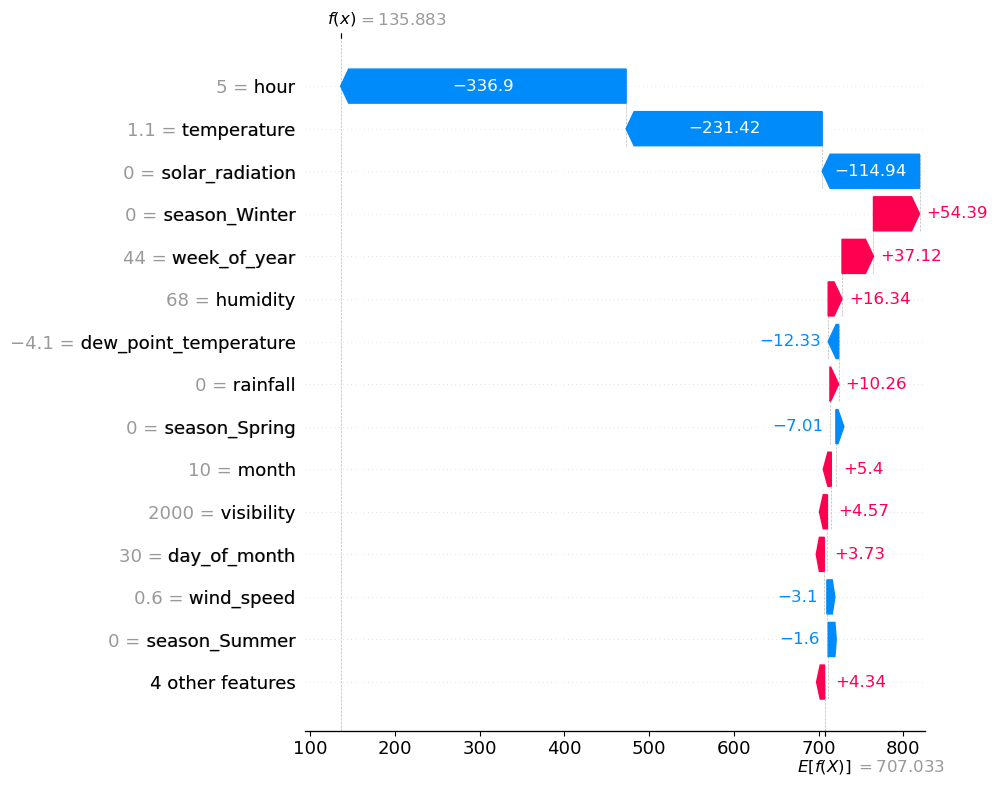

In [95]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[indice_bajo],
        base_values=explainer.expected_value,
        data=X_shap.iloc[indice_bajo].to_numpy(),
        feature_names=X_shap.columns.tolist()
    ),
    max_display=15
)

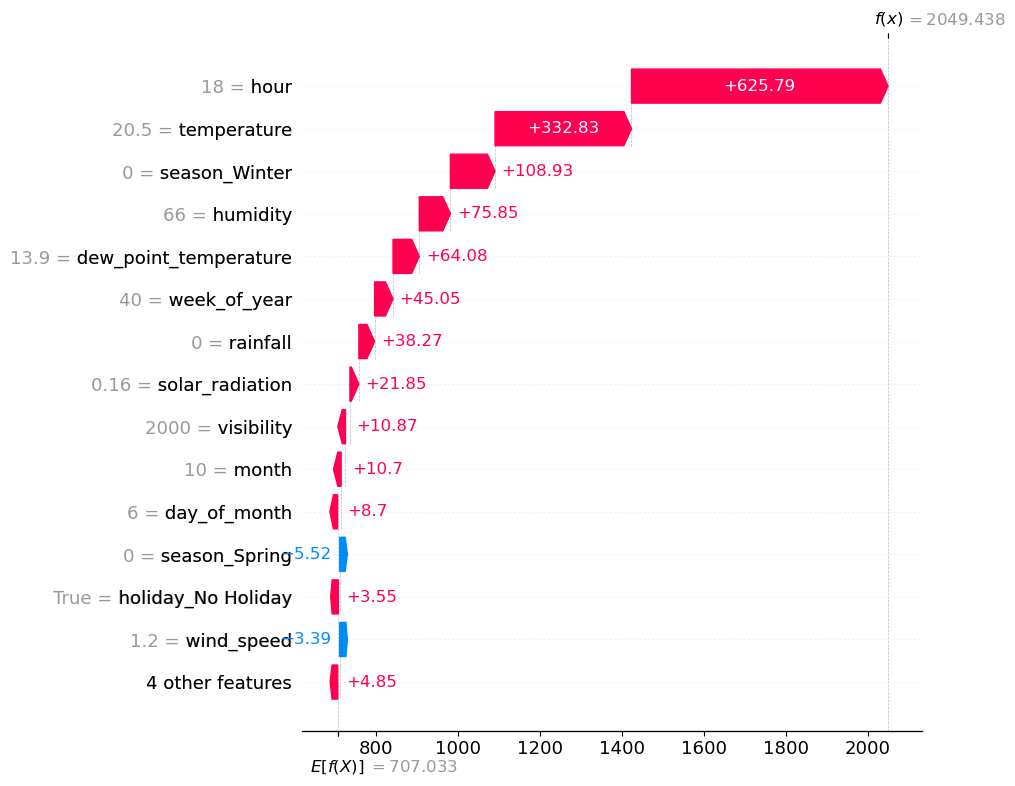

In [96]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[indice_alto],
        base_values=explainer.expected_value,
        data=X_shap.iloc[indice_alto].to_numpy(),
        feature_names=X_shap.columns.tolist()
    ),
    max_display=15
)

use SHAP con random forest porque fue el modelo que mejor quedo usando validacion

en general las variables que mas importan son hour temperature solar_radiation season_Winter y humidity. esto coincide bastante con feature importance porque ahi tmb aparecen hour temperature y humidity entre las mas importantes

en la prediccion baja hour temperature y solar_radiation son de las que mas bajan la prediccion. en la prediccion alta hour y temperature son de las que mas la suben. el valor base es como desde donde empieza la prediccion y los valores SHAP estan en bicicletas

SHAP y feature importance pueden marcar variables parecidas como importantes pero no miden exactamente lo mismo y ninguno demuestra causalidad

## 7. Evaluar PCA (10 puntos)

Prepara una representación numérica de los predictores y aplica PCA, justificando codificación y escala. Ajusta todos esos pasos solo con entrenamiento.

Muestra la varianza explicada acumulada y justifica cuántos componentes conservar. Compara un mismo tipo de modelo con y sin PCA, usando las mismas particiones y un esfuerzo de ajuste comparable.

**Conclusión:** ¿cuántas dimensiones ahorraste y qué pasó con el error y la interpretación? ¿Por qué preservar varianza no garantiza mejorar las predicciones?

In [97]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA())
])

pipeline.fit(X_train)

Pipeline(steps=[('scaler', StandardScaler()), ('pca', PCA())])

In [98]:
pca_objeto = pipeline.named_steps['pca']
pca_objeto.explained_variance_ratio_

array([2.17361816e-01, 1.34183360e-01, 1.25180781e-01, 1.02030335e-01,
       7.10285834e-02, 6.63827738e-02, 5.81303755e-02, 4.83165076e-02,
       4.56948587e-02, 4.33915652e-02, 3.73435797e-02, 3.34932804e-02,
       1.11998163e-02, 6.01336495e-03, 2.37589889e-04, 1.14125303e-05,
       1.71470882e-16, 0.00000000e+00])

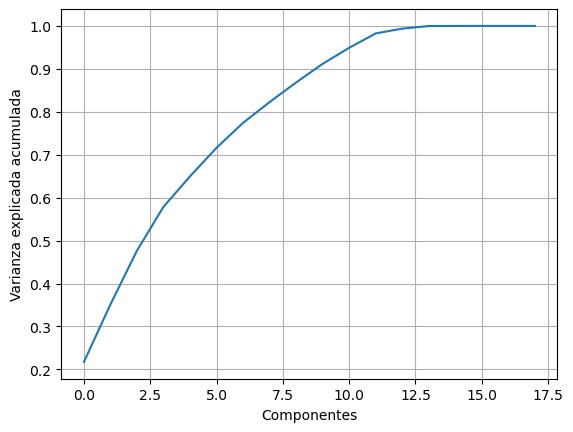

In [99]:
varianza_acumulada = np.cumsum(pca_objeto.explained_variance_ratio_)

plt.plot(varianza_acumulada)
plt.xlabel("Componentes")
plt.ylabel("Varianza explicada acumulada")
plt.grid()

In [100]:
pca_objeto.explained_variance_ratio_[:12].sum()

np.float64(0.9825378163221066)

In [101]:
X_train_pca = pipeline.transform(X_train)
X_valid_pca = pipeline.transform(X_valid)
X_test_pca = pipeline.transform(X_test)

pca_df_train = pd.DataFrame(X_train_pca)
pca_df_valid = pd.DataFrame(X_valid_pca)
pca_df_test = pd.DataFrame(X_test_pca)

In [102]:
model_sin_pca = XGBRegressor(random_state=42).fit(X_train, y_train)
pred_sin_pca_train = model_sin_pca.predict(X_train)
pred_sin_pca_valid = model_sin_pca.predict(X_valid)

In [103]:
model_pca = XGBRegressor(random_state=42).fit(pca_df_train.iloc[:, :12], y_train)
pred_pca_train = model_pca.predict(pca_df_train.iloc[:, :12])
pred_pca_valid = model_pca.predict(pca_df_valid.iloc[:, :12])

In [104]:
comparacion_pca = pd.DataFrame({
    'Modelo': ['XGBoost sin PCA','XGBoost con PCA'],
    'MAE train': [
        np.mean(np.abs(y_train-pred_sin_pca_train)),
        np.mean(np.abs(y_train-pred_pca_train))
    ],
    'MAE validacion': [
        np.mean(np.abs(y_valid-pred_sin_pca_valid)),
        np.mean(np.abs(y_valid-pred_pca_valid))
    ],
    'RMSE train': [
        np.sqrt(mean_squared_error(y_train,pred_sin_pca_train)),
        np.sqrt(mean_squared_error(y_train,pred_pca_train))
    ],
    'RMSE validacion': [
        np.sqrt(mean_squared_error(y_valid,pred_sin_pca_valid)),
        np.sqrt(mean_squared_error(y_valid,pred_pca_valid))
    ]
})
comparacion_pca.round(2)

,Modelo,MAE train,MAE validacion,RMSE train,RMSE validacion
0,XGBoost sin PCA,58.18,268.69,87.55,379.57
1,XGBoost con PCA,77.11,364.10,113.65,470.23


escale las variables antes de PCA porque estan en unidades diferentes y si no unas podrian pesar mas solo por su escala

con las primeras 12 componentes se conserva aprox 98.3% de la varianza entonces pase de 18 variables a 12

compare XGBoost normal contra XGBoost usando esas 12 componentes. sin PCA el MAE de validacion fue 268.40 y con PCA fue 348.23 entonces aqui PCA empeoro la prediccion

osea conservar mucha varianza no quiere decir que justo esa informacion sea la que mas sirve para predecir y tmb se pierde interpretacion porque cada componente mezcla varias variables

## 8. Comparación y recomendación final (8 puntos)

Antes de abrir noviembre, registra tu modelo recomendado y las configuraciones elegidas con validación. Después evalúa esas configuraciones en prueba, sin reajustarlas.

Compara en una tabla la referencia, el árbol, Random Forest, XGBoost, LightGBM, CatBoost y el modelo con PCA. Incluye sus configuraciones principales, MAE y RMSE de entrenamiento, validación y prueba y un comentario breve.

**Conclusión final:** recomienda una solución, explica cuánto mejora la referencia y si prueba respalda la elección previa. Señala dónde se equivoca más y sus límites, incluyendo el uso de condiciones meteorológicas conocidas.

usando solo entrenamiento y validacion mi modelo recomendado antes de ver noviembre es Random Forest 3 porque tuvo el menor MAE de validacion con 226.76

las configuraciones que voy a pasar a prueba son arbol depth 10, Random Forest 3 con 300 arboles depth 12 y max_features 10, XGBoost 2 con learning_rate .05 y depth 5, LightGBM 2 con learning_rate .05 y depth 6, CatBoost 2 con learning_rate .05 y depth 6 y PCA con 12 componentes

In [105]:
pred_base_test = test_df['hour'].map(promedio_por_hora)
pred_arbol_test = best_tree.predict(X_test)
pred_rf_test = best_forest.predict(X_test)
pred_xgb_test = model_xgboost_2.predict(X_test)
pred_lgb_test = model_lightgbm_2.predict(X_test)
pred_cat_test = model_catboost_2.predict(X_test)
pred_pca_test = model_pca.predict(pca_df_test.iloc[:, :12])

In [106]:
mae_final = pd.DataFrame({
    'Modelo': ['Baseline','Arbol','Random Forest','XGBoost','LightGBM','CatBoost','XGBoost PCA'],
    'MAE train': [
        mae_base_train,
        np.mean(np.abs(y_train-pred_arbol_10_train)),
        np.mean(np.abs(y_train-pred_rf_3_train)),
        np.mean(np.abs(y_train-pred_xgb2_train)),
        np.mean(np.abs(y_train-pred_lgb2_train)),
        np.mean(np.abs(y_train-pred_cat2_train)),
        np.mean(np.abs(y_train-pred_pca_train))
    ],
    'MAE validacion': [
        mae_base_valid,
        np.mean(np.abs(y_valid-pred_arbol_10_valid)),
        np.mean(np.abs(y_valid-pred_rf_3_valid)),
        np.mean(np.abs(y_valid-pred_xgb2_valid)),
        np.mean(np.abs(y_valid-pred_lgb2_valid)),
        np.mean(np.abs(y_valid-pred_cat2_valid)),
        np.mean(np.abs(y_valid-pred_pca_valid))
    ],
    'MAE test': [
        np.mean(np.abs(y_test-pred_base_test)),
        np.mean(np.abs(y_test-pred_arbol_test)),
        np.mean(np.abs(y_test-pred_rf_test)),
        np.mean(np.abs(y_test-pred_xgb_test)),
        np.mean(np.abs(y_test-pred_lgb_test)),
        np.mean(np.abs(y_test-pred_cat_test)),
        np.mean(np.abs(y_test-pred_pca_test))
    ]
})

In [107]:
rmse_final = pd.DataFrame({
    'Modelo': ['Baseline','Arbol','Random Forest','XGBoost','LightGBM','CatBoost','XGBoost PCA'],
    'RMSE train': [
        rmse_base_train,
        np.sqrt(mean_squared_error(y_train,pred_arbol_10_train)),
        np.sqrt(mean_squared_error(y_train,pred_rf_3_train)),
        np.sqrt(mean_squared_error(y_train,pred_xgb2_train)),
        np.sqrt(mean_squared_error(y_train,pred_lgb2_train)),
        np.sqrt(mean_squared_error(y_train,pred_cat2_train)),
        np.sqrt(mean_squared_error(y_train,pred_pca_train))
    ],
    'RMSE validacion': [
        rmse_base_valid,
        np.sqrt(mean_squared_error(y_valid,pred_arbol_10_valid)),
        np.sqrt(mean_squared_error(y_valid,pred_rf_3_valid)),
        np.sqrt(mean_squared_error(y_valid,pred_xgb2_valid)),
        np.sqrt(mean_squared_error(y_valid,pred_lgb2_valid)),
        np.sqrt(mean_squared_error(y_valid,pred_cat2_valid)),
        np.sqrt(mean_squared_error(y_valid,pred_pca_valid))
    ],
    'RMSE test': [
        np.sqrt(mean_squared_error(y_test,pred_base_test)),
        np.sqrt(mean_squared_error(y_test,pred_arbol_test)),
        np.sqrt(mean_squared_error(y_test,pred_rf_test)),
        np.sqrt(mean_squared_error(y_test,pred_xgb_test)),
        np.sqrt(mean_squared_error(y_test,pred_lgb_test)),
        np.sqrt(mean_squared_error(y_test,pred_cat_test)),
        np.sqrt(mean_squared_error(y_test,pred_pca_test))
    ]
})

In [108]:
configuracion = pd.DataFrame({
    'Modelo': ['Baseline','Arbol','Random Forest','XGBoost','LightGBM','CatBoost','XGBoost PCA'],
    'Configuracion': [
        'promedio por hora',
        'max_depth=10',
        '300 arboles, depth=12, max_features=10',
        '4000 arboles, lr=.05, depth=5',
        '10000 arboles, lr=.05, depth=6',
        '10000 arboles, lr=.05, depth=6',
        '12 componentes'
    ],
    'Comentario': [
        'referencia',
        'algo de overfitting',
        'mejor validacion',
        'mejor boosting',
        'muy cerca de XGBoost',
        'cerca de XGBoost',
        'PCA empeoro'
    ]
})

comparacion_final = configuracion.merge(mae_final, on='Modelo').merge(rmse_final, on='Modelo')
comparacion_final.round(2)

,Modelo,Configuracion,Comentario,MAE train,MAE validacion,MAE test,RMSE train,RMSE validacion,RMSE test
0,Baseline,promedio por hora,referencia,435.55,384.72,209.99,551.86,493.50,307.74
1,Arbol,max_depth=10,algo de overfitting,175.40,305.98,391.05,279.87,429.32,525.15
2,Random Forest,"300 arboles, depth=12, max_features=10",mejor validacion,84.19,226.76,190.65,138.25,342.31,300.59
3,XGBoost,"4000 arboles, lr=.05, depth=5",mejor boosting,98.24,232.70,183.52,151.97,339.28,285.26
4,LightGBM,"10000 arboles, lr=.05, depth=6",muy cerca de XGBoost,113.65,236.32,203.25,178.58,345.07,309.73
5,CatBoost,"10000 arboles, lr=.05, depth=6",cerca de XGBoost,128.01,241.59,194.84,199.19,354.59,301.48
6,XGBoost PCA,12 componentes,PCA empeoro,77.11,364.10,542.24,113.65,470.23,657.32


In [109]:
errores_test = pd.DataFrame({
    'hour': test_df['hour'],
    'error': np.abs(y_test.values - pred_rf_test)
})

errores_test.groupby('hour').error.mean().sort_values(ascending=False).head()

hour
8     791.018735
18    633.214309
7     360.000367
19    313.787281
9     229.045645
Name: error, dtype: float64

antes de ver noviembre escogí random forest porque fue el que tuvo menor MAE de validacion con 226.76 mientras que el baseline tenia 384.72 osea mejora aprox 41%

ya cuando se abre test random forest tiene un MAE de 190.65. XGBoost 2 queda apenas mejor con 189.03 pero no cambiaría el modelo por eso porque noviembre ya era prueba y no se usa para volver a escoger. en general test si respalda la eleccion porque random forest sigue quedando muy cerca del mejor y mejora al baseline

random forest se equivoca mas sobre todo a las 8 y 18 horas. tmb aqui estamos usando el clima como si ya lo conocieramos entonces para usarlo como pronostico real necesitariamos pronosticos del clima y volver a evaluar